In [2]:
import numpy as np
import scipy as sp

import matplotlib.pyplot as plt
%matplotlib inline

from scipy.integrate import simps
from scipy.integrate import quad
from scipy import interpolate

import importlib

In [93]:
from radmodel import uprint

import FridgeModel
importlib.reload(FridgeModel)
from FridgeModel import *

In [5]:
L_ShelltoVCS2 = 20 * 0.0254
A_ShelltoVCS2 = ringArea(38.5*0.0254, 0.125*0.0254)

L_VCS2toVCS1 = 9.25 * 0.0254
A_VCS2toVCS1 = ringArea(35.5*0.0254, 0.0625*0.0254)

L_VCS1toMT = 15.75 * 0.0254
A_VCS1toMT = ringArea(34*0.0254, 0.04*0.0254)

L_MTtoSFT = 3.8 * 0.0254
A_MTtoSFT = ringArea(3.24*0.0254, 0.02*0.0254)


print(A_ShelltoVCS2/L_ShelltoVCS2)

0.019138680620439417


### LN equlibrium

In [94]:
model = ThermalSystem(name='TIM cryostat LN')
stages = [Stages(name='VV', T0=293), Stages(name='vcs2', T0=244, Wt=55), \
          Stages(name='vcs1', T0=190, Wt=45), Stages(name='tank', T0=77)]

model.add_stages(stages)

# radiation
model.add_linkage(MLI(name='Rad_shell_vcs2', area = 6.22, N=20, s1=model.stages[0], \
                            s2=model.stages[1]))
model.add_linkage(MLI(name='Rad_vcs2_vcs1', area = 5.15, N=20, s1=model.stages[1], \
                            s2=model.stages[2]))
model.add_linkage(MLI(name='Rad_vcs1_tank', area = 4.43, N=10, P=1e-6, optical=0, s1=model.stages[2], \
                            s2=model.stages[3]))


# G10
G10_AL = A_ShelltoVCS2/L_ShelltoVCS2
model.add_linkage(Cond(name='G10_shell_vcs2', AOverL = G10_AL, material=G10, s1=model.stages[0], \
                            s2=model.stages[1]))

G10_AL2 = A_VCS2toVCS1/L_VCS2toVCS1
model.add_linkage(Cond(name='G10_vcs2_vcs1', AOverL = G10_AL2, material=G10, s1=model.stages[1], \
                            s2=model.stages[2]))
              
G10_AL3 = A_VCS1toMT/L_VCS1toMT
model.add_linkage(Cond(name='G10_vcs1_tank', AOverL = G10_AL3, material=G10, s1=model.stages[2], \
                            s2=model.stages[3]))


# Plumbing
PLB_AL = 8.58418E-05
model.add_linkage(Cond(name='Fill_tube_shell_vcs2', AOverL = PLB_AL, material=SS316, s1=model.stages[0], \
                            s2=model.stages[1]))

PLB_AL2 = 7.24358E-05
model.add_linkage(Cond(name='Fill_tube_vcs2_vcs1', AOverL = PLB_AL2, material=SS316, s1=model.stages[1], \
                            s2=model.stages[2]))
              
PLB_AL3 = 1.26962e-04
model.add_linkage(Cond(name='Fill_tube_vcs1_tank', AOverL = PLB_AL3, material=SS316, s1=model.stages[2], \
                            s2=model.stages[3]))



# # coaxial cables to the FPU, 8 for each module
# coax_corss_section = np.pi*(2.19e-3**2 - 1.67e-3**2 + 0.51e-3**2)/4.
# # coax_corss_section = np.pi*(1.19e-3**2 - 0.94e-3**2 + 0.287e-3**2)/4.
# # coax_corss_section = np.pi*(0.86e-3**2 - 0.66e-3**2 + 0.230e-3**2)/4.

# coax_AOverL = (8*2)*coax_corss_section/0.15
# model.add_linkage(Cond(name='Coax_shell_vcs2', AOverL = coax_AOverL, material=SS, s1=model.stages[0], \
#                             s2=model.stages[1]))

# coax_AOverL2 = (8*2)*coax_corss_section/0.15
# model.add_linkage(Cond(name='Coax_vcs2_vcs1', AOverL = coax_AOverL2, material=SS, s1=model.stages[1], \
#                             s2=model.stages[2]))

# coax_AOverL3 = (8*2)*coax_corss_section/0.75
# model.add_linkage(Cond(name='Coax_vcs1_tank', AOverL = coax_AOverL3, material=SS, s1=model.stages[2], \
#                             s2=model.stages[3]))



# HK wires
HKwire_cross_srction = 0.127e-3**2 *np.pi/4.  # 36 AWG

N1,N2,N3 = 150,150,150

HKwL1 = .15
HKwL2 = .1
HKwL3 = .65


model.add_linkage(Cond(name='HKw_shell_vcs2', AOverL = N1*HKwire_cross_srction/HKwL1, material=PhBr, s1=model.stages[0], \
                            s2=model.stages[1]))
model.add_linkage(Cond(name='HKw_vcs2_vcs1', AOverL = N2*HKwire_cross_srction/HKwL2, material=PhBr, s1=model.stages[1], \
                            s2=model.stages[2]))
model.add_linkage(Cond(name='HKw_vcs1_tank', AOverL = N3*HKwire_cross_srction/HKwL3, material=PhBr, s1=model.stages[2], \
                            s2=model.stages[3]))


# model.add_linkage(Source(name='LNAs', s1=model.stages[0], s2=model.stages[3], flux=1.7*6e-3*8))

model.showSystem()
# model.calLoads()
# stageLoads = model.getLoads()
# model.showLoads()

System: TIM cryostat LN
Stages:
   VV , Temp: 293.00K
   vcs2 , Temp: 244.00K
   vcs1 , Temp: 190.00K
   tank , Temp: 77.00K
Linkages:
  Rad_shell_vcs2    	 | VV to vcs2	 | MLI
  Rad_vcs2_vcs1     	 | vcs2 to vcs1	 | MLI
  Rad_vcs1_tank     	 | vcs1 to tank	 | MLI
  G10_shell_vcs2    	 | VV to vcs2	 | Conduction	 | G10, A/L: 1.91e-02 m
  G10_vcs2_vcs1     	 | vcs2 to vcs1	 | Conduction	 | G10, A/L: 1.91e-02 m
  G10_vcs1_tank     	 | vcs1 to tank	 | Conduction	 | G10, A/L: 6.88e-03 m
  Fill_tube_shell_vcs2	 | VV to vcs2	 | Conduction	 | SS316, A/L: 8.58e-05 m
  Fill_tube_vcs2_vcs1	 | vcs2 to vcs1	 | Conduction	 | SS316, A/L: 7.24e-05 m
  Fill_tube_vcs1_tank	 | vcs1 to tank	 | Conduction	 | SS316, A/L: 1.27e-04 m
  HKw_shell_vcs2    	 | VV to vcs2	 | Conduction	 | PhBr, A/L: 1.27e-05 m
  HKw_vcs2_vcs1     	 | vcs2 to vcs1	 | Conduction	 | PhBr, A/L: 1.90e-05 m
  HKw_vcs1_tank     	 | vcs1 to tank	 | Conduction	 | PhBr, A/L: 2.92e-06 m


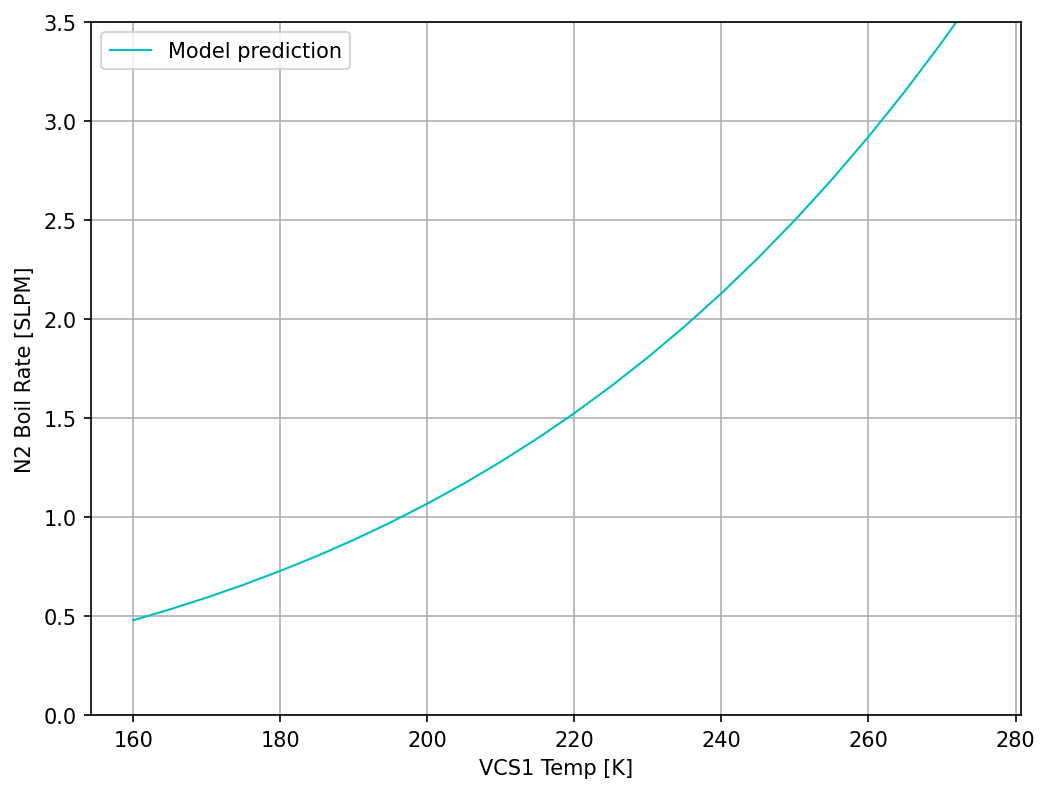

In [7]:
T_VCS1 = np.arange(160,280, 5)
Tank_load = []

for T in T_VCS1:
    model.stages[2].T = T
    model.calLoads()
    Tank_load.append(model.stages[3].load)

Tank_load = np.array(Tank_load)
Tank_FR = mdot2SLPM(power2mdot(Tank_load, gas='N'), gas='N')

plt.plot(T_VCS1, Tank_FR, c='c', label='Model prediction')

plt.ylim([0,3.5])

plt.xlabel('VCS1 Temp [K]')
plt.ylabel('N2 Boil Rate [SLPM]')
plt.legend()
plt.grid()

In [97]:
model.stages[1].T = 225
model.stages[2].T = 160
model.stages[3].T = 77

model.findEq(eff=[.95, .95], gas='N', gain=5, tankP=0)

VCS1 Temp: 254.49
VCS2 Temp: 190.62
In 34 steps



([254.49280428391816, 190.62115812654883], 34)

In [9]:
# model.showSystem()
model.calLoads()
stageLoads = model.getLoads()
model.showLoads()

Fluxes and Loadings on stages:
  On vcs2 Stage: 
    Link: Rad_shell_vcs2     | VV to vcs2	 | Flux:  11.974  W
    Link: G10_shell_vcs2     | VV to vcs2	 | Flux:  923.497 mW
    Link: Fill_tube_shell_vcs2 | VV to vcs2	 | Flux:  110.934 mW
    Link: HKw_shell_vcs2     | VV to vcs2	 | Flux:  103.619 mW
    -----------
    Net Loading on this stage: 		  8.777  W 

  On vcs1 Stage: 
    Link: Rad_vcs2_vcs1      | vcs2 to vcs1	 | Flux:   3.545  W
    Link: G10_vcs2_vcs1      | vcs2 to vcs1	 | Flux:  631.064 mW
    Link: Fill_tube_vcs2_vcs1 | vcs2 to vcs1	 | Flux:  70.641 mW
    Link: HKw_vcs2_vcs1      | vcs2 to vcs1	 | Flux:  88.048 mW
    -----------
    Net Loading on this stage: 		  3.766  W 

  On tank Stage: 
    Link: Rad_vcs1_tank      | vcs1 to tank	 | Flux:  445.954 mW
    Link: G10_vcs1_tank      | vcs1 to tank	 | Flux:  77.154 mW
    Link: Fill_tube_vcs1_tank | vcs1 to tank	 | Flux:  41.983 mW
    Link: HKw_vcs1_tank      | vcs1 to tank	 | Flux:   3.737 mW
    -----------
    Ne

### LHe Temp

In [32]:
model = ThermalSystem(name='TIM cryostat')
stages = [Stages(name='VV', T0=293), Stages(name='vcs2', T0=190, Wt=55), \
          Stages(name='vcs1', T0=60, Wt=45), Stages(name='tank', T0=4.2)]

model.add_stages(stages)

# radiation
model.add_linkage(MLI(name='Rad_shell_vcs2', area = 6.22, N=20, s1=model.stages[0], \
                            s2=model.stages[1]))
model.add_linkage(MLI(name='Rad_vcs2_vcs1', area = 5.15, N=20, s1=model.stages[1], \
                            s2=model.stages[2]))
model.add_linkage(MLI(name='Rad_vcs1_tank', area = 4.43, N=10, P=1e-6, optical=0, s1=model.stages[2], \
                            s2=model.stages[3]))


# G10
G10_AL = A_ShelltoVCS2/L_ShelltoVCS2
model.add_linkage(Cond(name='G10_shell_vcs2', AOverL = G10_AL, material=G10, s1=model.stages[0], \
                            s2=model.stages[1]))

G10_AL2 = A_VCS2toVCS1/L_VCS2toVCS1
model.add_linkage(Cond(name='G10_vcs2_vcs1', AOverL = G10_AL2, material=G10, s1=model.stages[1], \
                            s2=model.stages[2]))
              
G10_AL3 = A_VCS1toMT/L_VCS1toMT
model.add_linkage(Cond(name='G10_vcs1_tank', AOverL = G10_AL3, material=G10, s1=model.stages[2], \
                            s2=model.stages[3]))


# Plumbing
PLB_AL = 8.58418E-05
model.add_linkage(Cond(name='Fill_tube_shell_vcs2', AOverL = PLB_AL, material=SS316, s1=model.stages[0], \
                            s2=model.stages[1]))

PLB_AL2 = 7.24358E-05
model.add_linkage(Cond(name='Fill_tube_vcs2_vcs1', AOverL = PLB_AL2, material=SS316, s1=model.stages[1], \
                            s2=model.stages[2]))
              
PLB_AL3 = 1.26962e-04
model.add_linkage(Cond(name='Fill_tube_vcs1_tank', AOverL = PLB_AL3, material=SS316, s1=model.stages[2], \
                            s2=model.stages[3]))



# coaxial cables to the FPU, 8 for each module
coax_corss_section = np.pi*(2.19e-3**2 - 1.67e-3**2 + 0.51e-3**2)/4.
pair = 1


coax_AOverL = (pair*2)*coax_corss_section/0.1
model.add_linkage(Cond(name='Coax_shell_vcs2', AOverL = coax_AOverL, material=SS316, s1=model.stages[0], \
                            s2=model.stages[1]))

coax_AOverL2 = (pair*2)*coax_corss_section/0.15
model.add_linkage(Cond(name='Coax_vcs2_vcs1', AOverL = coax_AOverL2, material=SS316, s1=model.stages[1], \
                            s2=model.stages[2]))

# coax_AOverL3 = (8*2)*coax_corss_section/0.75
# model.add_linkage(Cond(name='Coax_vcs1_tank', AOverL = coax_AOverL3, material=SS316, s1=model.stages[2], \
#                             s2=model.stages[3]))



# HK wires
HKwire_cross_srction = 0.127e-3**2 *np.pi/4.  # 36 AWG

N1,N2,N3 = 150,150,150

HKwL1 = .15
HKwL2 = .1
HKwL3 = .65


model.add_linkage(Cond(name='HKw_shell_vcs2', AOverL = N1*HKwire_cross_srction/HKwL1, material=PhBr, s1=model.stages[0], \
                            s2=model.stages[1]))
model.add_linkage(Cond(name='HKw_vcs2_vcs1', AOverL = N2*HKwire_cross_srction/HKwL2, material=PhBr, s1=model.stages[1], \
                            s2=model.stages[2]))
model.add_linkage(Cond(name='HKw_vcs1_tank', AOverL = N3*HKwire_cross_srction/HKwL3, material=PhBr, s1=model.stages[2], \
                            s2=model.stages[3]))

# model.add_linkage(Source(name='LNAs', s1=model.stages[0], s2=model.stages[3], flux=1.7*6e-3*8))
# model.add_linkage(Source(name='light', s1=model.stages[0], s2=model.stages[3], flux=0.05))
model.add_linkage(Source(name='fridge', s1=model.stages[0], s2=model.stages[3], flux=0.03))



model.showSystem()

System: TIM cryostat
Stages:
   VV , Temp: 293.00K
   vcs2 , Temp: 190.00K
   vcs1 , Temp: 60.00K
   tank , Temp: 4.20K
Linkages:
  Rad_shell_vcs2    	 | VV to vcs2	 | MLI
  Rad_vcs2_vcs1     	 | vcs2 to vcs1	 | MLI
  Rad_vcs1_tank     	 | vcs1 to tank	 | MLI
  G10_shell_vcs2    	 | VV to vcs2	 | Conduction	 | G10, A/L: 1.91e-02 m
  G10_vcs2_vcs1     	 | vcs2 to vcs1	 | Conduction	 | G10, A/L: 1.91e-02 m
  G10_vcs1_tank     	 | vcs1 to tank	 | Conduction	 | G10, A/L: 6.88e-03 m
  Fill_tube_shell_vcs2	 | VV to vcs2	 | Conduction	 | SS316, A/L: 8.58e-05 m
  Fill_tube_vcs2_vcs1	 | vcs2 to vcs1	 | Conduction	 | SS316, A/L: 7.24e-05 m
  Fill_tube_vcs1_tank	 | vcs1 to tank	 | Conduction	 | SS316, A/L: 1.27e-04 m
  Coax_shell_vcs2   	 | VV to vcs2	 | Conduction	 | SS316, A/L: 3.56e-05 m
  Coax_vcs2_vcs1    	 | vcs2 to vcs1	 | Conduction	 | SS316, A/L: 2.37e-05 m
  HKw_shell_vcs2    	 | VV to vcs2	 | Conduction	 | PhBr, A/L: 1.27e-05 m
  HKw_vcs2_vcs1     	 | vcs2 to vcs1	 | Conduction	 | PhBr

In [33]:
model.stages[0].T = 290

model.findEq(eff=[0.95,0.95], gas='He', gain=1,)


model.calLoads()
stageLoads = model.getLoads()
model.showLoads()
model.showHoldtime()

VCS1 Temp: 178.98
VCS2 Temp: 62.17
In 42 steps

Fluxes and Loadings on stages:
  On vcs2 Stage: 
    Link: Rad_shell_vcs2     | VV to vcs2	 | Flux:  12.730  W
    Link: G10_shell_vcs2     | VV to vcs2	 | Flux:   1.061  W
    Link: Fill_tube_shell_vcs2 | VV to vcs2	 | Flux:  129.230 mW
    Link: Coax_shell_vcs2    | VV to vcs2	 | Flux:  53.616 mW
    Link: HKw_shell_vcs2     | VV to vcs2	 | Flux:  116.860 mW
    -----------
    Net Loading on this stage: 		  9.212  W 

  On vcs1 Stage: 
    Link: Rad_vcs2_vcs1      | vcs2 to vcs1	 | Flux:   3.924  W
    Link: G10_vcs2_vcs1      | vcs2 to vcs1	 | Flux:  749.919 mW
    Link: Fill_tube_vcs2_vcs1 | vcs2 to vcs1	 | Flux:  83.818 mW
    Link: Coax_vcs2_vcs1     | vcs2 to vcs1	 | Flux:  27.474 mW
    Link: HKw_vcs2_vcs1      | vcs2 to vcs1	 | Flux:  94.099 mW
    -----------
    Net Loading on this stage: 		  4.572  W 

  On tank Stage: 
    Link: Rad_vcs1_tank      | vcs1 to tank	 | Flux:  202.285 mW
    Link: G10_vcs1_tank      | vcs1 to tan

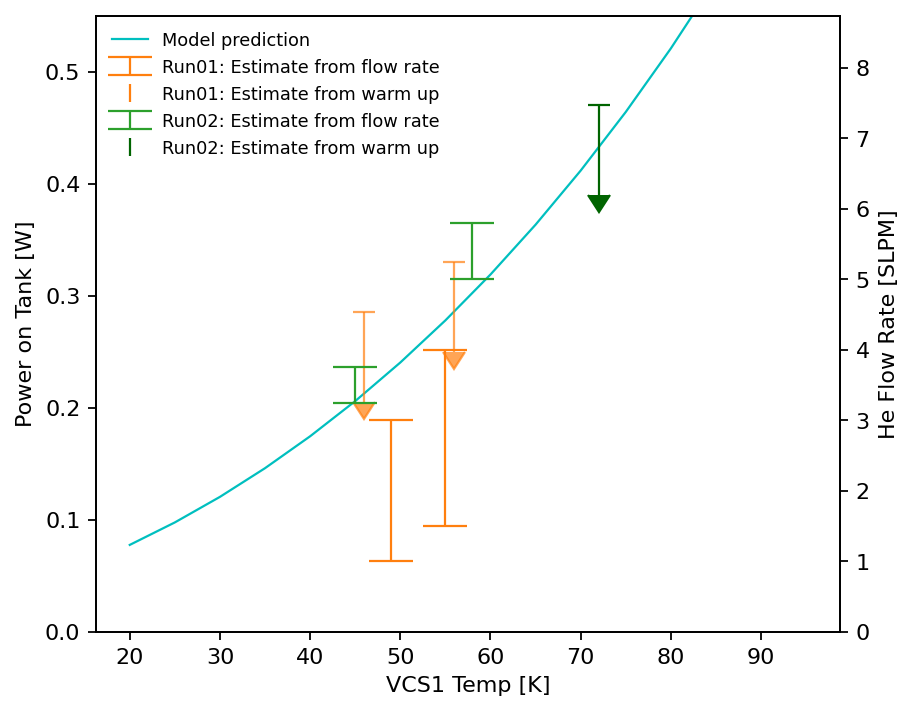

In [18]:
T_VCS1 = np.arange(20,100, 5)
Tank_load = []

for T in T_VCS1:
    model.stages[2].T = T
    model.calLoads()
    Tank_load.append(model.stages[3].load)

Tank_load = np.array(Tank_load)
Tank_FR = mdot2SLPM(power2mdot(Tank_load, gas='He'), gas='He')

fig, ax1 = plt.subplots(figsize=(6,5), dpi=160)

ax1.plot(T_VCS1, Tank_load, c='c', label='Model prediction')

# Estimate from warm up on Jan 26
ax1.errorbar(46, 0.285, yerr=.08, uplims=1, fmt='o', lw=1, alpha=0.7, c='C1', markersize=0, capsize=5, markeredgewidth=1, )

# Estimate from warm up on Jan 29
ax1.errorbar(56, 0.330, yerr=.08, uplims=1, fmt='o', lw=1, alpha=0.7,  c='C1', markersize=0, capsize=5, markeredgewidth=1, )


ax1.errorbar(72, 0.470, yerr=.08, uplims=1, fmt='o', lw=1, c='darkgreen', markersize=0, capsize=5, markeredgewidth=1, )



ax1.set_xlabel('VCS1 Temp [K]')
ax1.set_ylabel('Power on Tank [W]')
ax1.set_ylim([0,0.55])

# ax1.grid(axis='x')


ax2 = ax1.twinx()
ymin, ymax = ax1.get_ylim()
mdot2power = mdot2SLPM(power2mdot(1, gas='He'), gas='He')
ax2.set_ylim(ymin*mdot2power, ymax*mdot2power)
ax2.set_ylabel('He Flow Rate [SLPM]')
# ax2.grid()

ax2.errorbar(49, 2, yerr=1, fmt='o', c='C1', lw=1, markersize=0, capsize=10, markeredgewidth=1, label='Run01: Estimate from flow rate ')
ax2.errorbar(55, 2.75, yerr=1.25, fmt='o', c='C1', lw=1, markersize=0, capsize=10, markeredgewidth=1, )
ax2.plot([], [], c='c', label='Model prediction')
ax2.errorbar([], [], yerr=.02, uplims=1, fmt='o', lw=1, c='C1', markersize=0, capsize=7, markeredgewidth=2, label='Run01: Estimate from warm up')


ax2.errorbar(58, 5.4, yerr=0.4, fmt='o', c='C2', lw=1, markersize=0, capsize=10, markeredgewidth=1, label='Run02: Estimate from flow rate')
ax2.errorbar(45, 3.5, yerr=0.25, fmt='o', c='C2', lw=1, markersize=0, capsize=10, markeredgewidth=1, )
ax2.errorbar([], [], yerr=.08, uplims=1, fmt='o', lw=1, c='darkgreen', markersize=0, capsize=7, markeredgewidth=2, label='Run02: Estimate from warm up')



# ax1.legend()
ax2.legend(loc=2, fontsize=8, frameon=0)

# ax3 = ax1.twinx()
# ax3.spines['right'].set_position(('outward', 40))
# ymin, ymax = ax2.get_ylim()
# mdot2br = 1/22.4*0.004/0.125*60*24
# ax3.set_ylim(ymin*mdot2br, ymax*mdot2br)
# ax3.set_ylabel('LHe Boil Rate [L/day]')

# plt.savefig('TIM_Run02_cryo_vs_model.png', dpi=160)


### Helium warm up calculation

In [86]:
cooling_pow = (50.5-4.2)*5193*2.5/mdot2SLPM(1)
cooling_pow

1.7895004233601073

In [87]:
# pow_heat = 0.15 #W
V = 280 #L
dens = 12.35 #@4.9k
cp = 6.89*1e3
mass = V/1e3 * dens


dT = 0.02/24/60 # warm up speed K/s

pow_heat = mass*cp*dT 
pow_heat

0.33091138888888894

In [88]:
# pow_heat = 0.15 #W
V = 280 #L
dens = 4.33 #@11.5k
cp = 5.37*1e3
mass = V/1e3 * dens


dT = 0.13/30/60 # warm up speed K/s

pow_heat = mass*cp*dT 
pow_heat

0.47020913333333336

### Transient study

In [116]:
setups = ['0 watt', '20 watt', '60 watt']
dps = [0,20,60]

tlist = []
Tstage_list = []


for i,dp in enumerate(dps):


    model.stages[1].T = 290
    model.stages[2].T = 290
    model.stages[3].T = 77

    t, T_stages = model.heatEq(tEnd=120*3600, dt=300, dp=dp, gas='N', eff=.95)

    tlist.append(t)
    Tstage_list.append(T_stages)



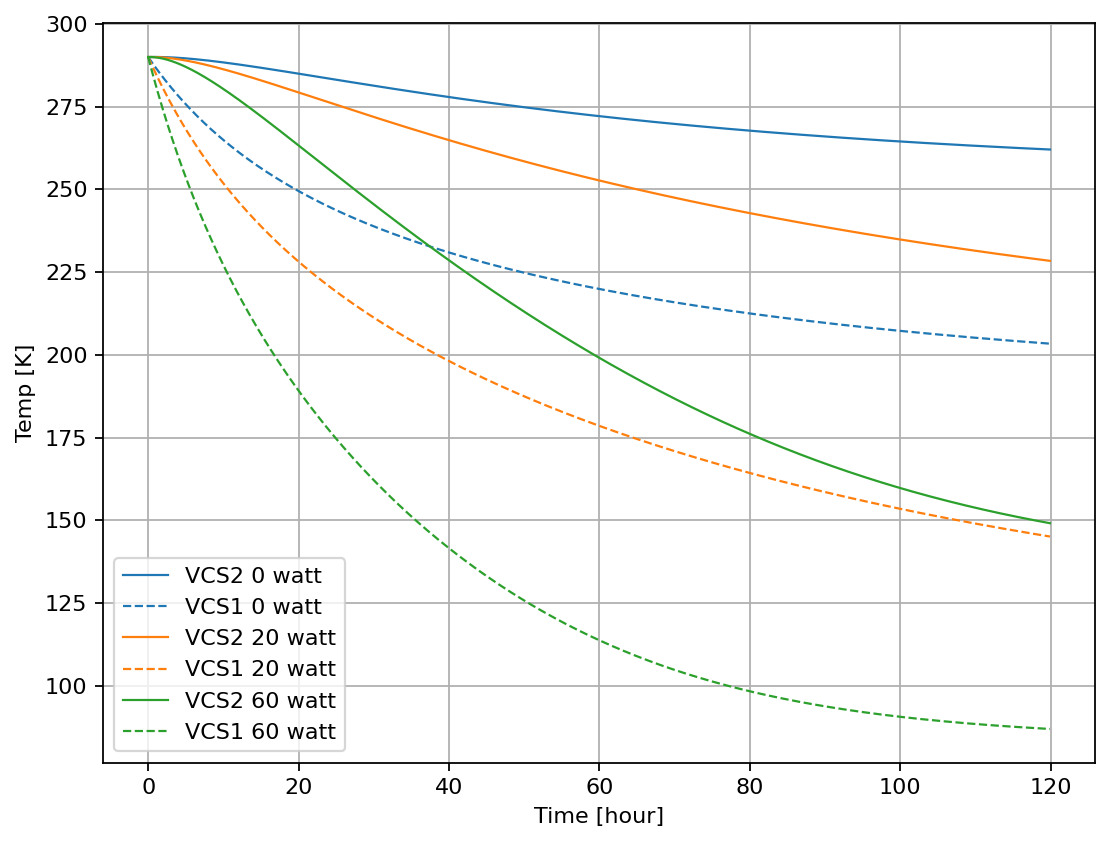

In [126]:
plt.figure(dpi=160)

style = ['-', '--', '-.']
C = ['C0', 'C1', 'C2']

for i,dp in enumerate(dps):

    plt.plot(tlist[i]/3600, Tstage_list[i][:,0], c=C[i], label='VCS2 %s'%setups[i])
    plt.plot(tlist[i]/3600, Tstage_list[i][:,1], '--', c=C[i], label='VCS1 %s'%setups[i])




# plt.plot(t2/3600, T_stages2[:,1]*0+77, label='Tank')
# plt.plot(t2/3600+48, T_stages2[:,0], 'C0' )
# plt.plot(t2/3600+48, T_stages2[:,1], 'C1')
# plt.plot(t2/3600+48, T_stages2[:,1]*0+4.4, 'C2')

# plt.yscale('log')

plt.xlabel('Time [hour]')
plt.ylabel('Temp [K]')
plt.legend()
plt.grid()

plt.savefig('VCS_equili_LN.png')
plt.show()

### Impact from pump cycling

In [177]:
model.stages[1].T = 184.3
model.stages[2].T = 65
model.stages[3].T = 4.2

t2, T_stages2 = model.heatEq(tEnd=72*3600, dt=600, gas='He', eff=0.95)
print(T_stages2[-1])

[184.18393251  64.9833354 ]


In [178]:
h_start = 1
h_dur = 4


t, T_stages = model.pumpImpact(tEnd=72*3600, dt=120, dp=0.3, dp_tStr=h_start*3600, dp_t=h_dur*3600)

In [162]:
outfile = 'vcs_temps_sim.npz'
np.savez(outfile, t, T_stages)

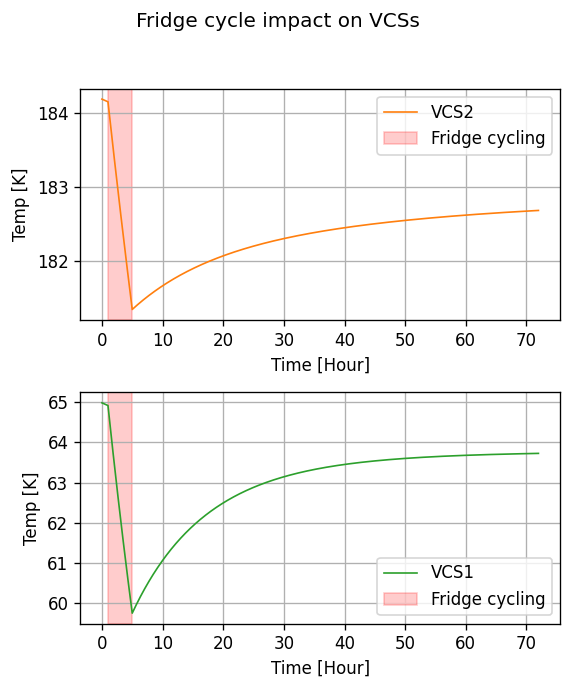

In [179]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5,6), dpi=120)

fig.suptitle('Fridge cycle impact on VCSs')


ax1.plot(t/3600, T_stages[:,0], c='C1', label='VCS2')

ax1.set_xlabel('Time [Hour]')
ax1.set_ylabel('Temp [K]')

ax1.axvspan(h_start, h_dur+h_start, color='r', alpha=0.2, label='Fridge cycling')

ax1.legend()
ax1.grid()


ax2.plot(t/3600, T_stages[:,1], c='C2', label='VCS1')

ax2.set_xlabel('Time [Hour]')
ax2.set_ylabel('Temp [K]')

ax2.axvspan(h_start, h_dur+h_start, color='r', alpha=0.2, label='Fridge cycling')

ax2.legend()
ax2.grid()

fig.tight_layout(rect=[0, 0.03, 1, 0.95])

# plt.savefig('VCS_fridge_impact.png')
plt.show()

In [158]:
from scipy.integrate import simpson,trapz,quad

# AL enpathy from 77 to 4 K in J
enp = quad(AlCp, 4.2, 77)[0] 

he_mass = enp/(84.5/0.004)
he_vol = he_mass/0.125

print(he_mass, he_vol)

0.4107532839987694 3.2860262719901554


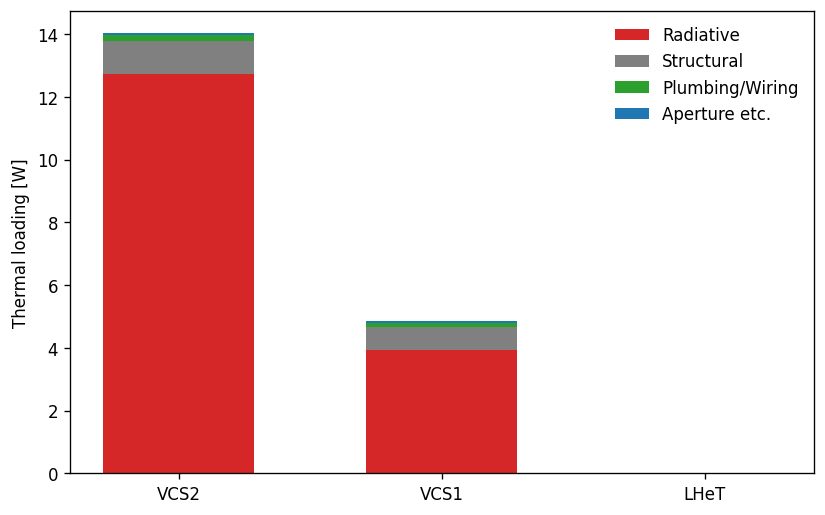

In [106]:

Rad = np.array([0, 3.92 , 12.73])[::-1]
Stru = np.array([0, 750.117e-3, 1.06])[::-1]
Plumb = np.array([0,	.113, 0.187])[::-1]
Aper = np.array([0, 66e-3, 53e-3])[::-1]


ind = np.array([1,2,3])*0.7   # the x locations for the groups
width = 0.4  # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(8,5), dpi=120)

p1 = plt.bar(ind, Rad, width, color='C3')
p2 = plt.bar(ind, Stru, width, bottom=Rad, color='gray')
p3 = plt.bar(ind, Plumb, width, bottom=Rad+Stru, color='C2')
p4 = plt.bar(ind, Aper, width, bottom=Rad+Stru+Plumb, color='C0')
# p4 = plt.bar(0, sft/S[0], width, bottom=(cable/S+rod/S+Rad/S)[0],)

# plt.yscale('log')
plt.ylabel('Thermal loading [W]')
plt.xticks(ind, ('VCS2', 'VCS1', 'LHeT',  ))
# plt.yticks(np.arange(0, 1.21, 0.1))
plt.legend((p1[0], p2[0], p3[0], p4[0]), ('Radiative', 'Structural', 'Plumbing/Wiring', 'Aperture etc.'), \
           frameon=False, loc=1)

# autolabel(p3,S)

# plt.savefig('Heat_fluxes_cryostat.png', dpi=160)
plt.show()

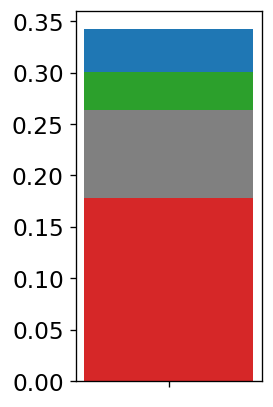

In [149]:

Rad = np.array([177.75e-3, ])
Stru = np.array([86.20e-3,])
Plumb = np.array([37E-03,	])
Aper = np.array([1.59e-3+40e-3, ])


ind = np.arange(1)*1   # the x locations for the groups
width = 0.6  # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(2,4), dpi=120)

p1 = plt.bar(ind, Rad, width, color='C3')
p2 = plt.bar(ind, Stru, width, bottom=Rad, color='gray')
p3 = plt.bar(ind, Plumb, width, bottom=Rad+Stru, color='C2')
p4 = plt.bar(ind, Aper, width, bottom=Rad+Stru+Plumb, color='C0')
# p4 = plt.bar(0, sft/S[0], width, bottom=(cable/S+rod/S+Rad/S)[0],)


# plt.ylabel('Power [W]')
plt.xticks(ind, ('', ))
plt.yticks(fontsize=14)
# plt.yticks(np.arange(0, 1.21, 0.1))

# autolabel(p3,S)

# plt.tight_layout()
plt.show()